# Netflix Country-Wise Content Analysis

## Project Overview

This project focuses on analyzing Netflix content based on country-wise distribution. It examines the number of Movies and TV Shows produced by different countries and compares their content contributions.

## Project Objectives

- Identify the top countries by Netflix content.
- Analyze country-wise Movies and TV Shows distribution.
- Compare Movies and TV Shows across different countries.
- Identify the top 10 countries separately for Movies and TV Shows.
- Create visualizations and generate meaningful insights.

## Dataset Information

- **Dataset:** Netflix Cleaned Dataset
- **Total Records:** 8,790
- **Total Columns:** 10
- **Countries Analyzed:** 85
- **Missing Values:** 0
- **Duplicate Records:** 0
- **Content Types:** Movies and TV Shows

## 1. Import Required Libraries

The following Python libraries are used for data analysis and visualization:

- **Pandas:** Data manipulation and analysis.
- **Matplotlib:** Creating charts and visualizations.
- **Seaborn:** Statistical data visualization.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Loading the Dataset

The cleaned Netflix dataset is loaded into a Pandas DataFrame using the `read_csv()` function.

The dataset is stored in the `data` folder of the project.

In [2]:
df = pd.read_csv("data/Netflix_Cleaned.csv")

df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


## 3. Initial Data Inspection

The dataset is inspected to understand its structure, dimensions, column names, and data types.

The `info()` function is used to check the dataset information and identify missing values.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB


In [4]:
df['country'].head(10)

0     United States
1            France
2     United States
3            Brazil
4     United States
5    United Kingdom
6     United States
7             India
8           Germany
9             India
Name: country, dtype: object

In [5]:
multiple_countries = df[df['country'].str.contains(',', na=False)]

print("Records with multiple countries:", len(multiple_countries))

multiple_countries[['title', 'country']].head(10)

Records with multiple countries: 0


,title,country


## 4. Country-Wise Content Analysis

The country column is analyzed to identify the countries with the highest number of Netflix titles.

The `value_counts()` function is used to calculate the number of titles associated with each country.

The `Not Given` category is excluded from the final country ranking because it does not represent an actual country.

In [6]:
df['country'].value_counts().head(15)

country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Egypt              123
Australia          114
Turkey             112
Nigeria            105
Name: count, dtype: int64

In [7]:
country_counts = df[df['country'] != 'Not Given']['country'].value_counts()

country_counts.head(15)

country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Egypt              123
Australia          114
Turkey             112
Nigeria            105
Germany            104
Name: count, dtype: int64

## 5. Country-Wise Content Visualization

A horizontal bar chart is created to visualize the top 15 countries with the highest number of Netflix titles.

This visualization helps identify the leading countries in Netflix content distribution.

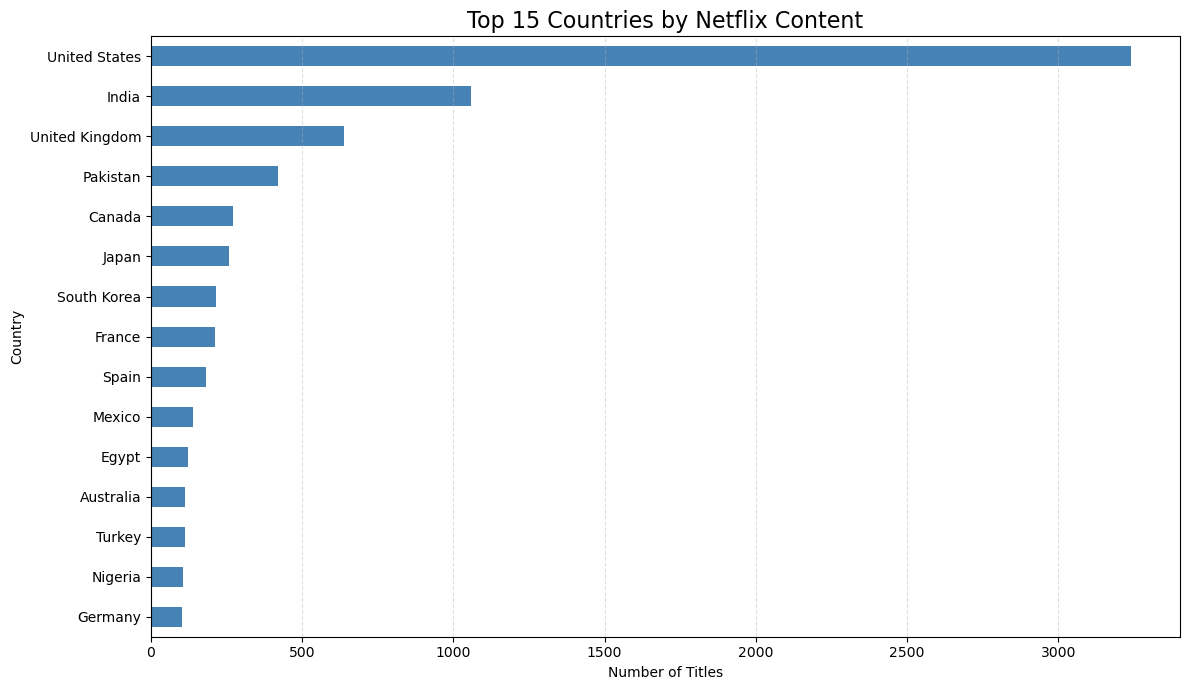

In [8]:
plt.figure(figsize=(12, 7))

country_counts.head(15).sort_values().plot(
    kind='barh',
    color='steelblue'
)

plt.title("Top 15 Countries by Netflix Content", fontsize=16)
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

## 6. Country-Wise Movies and TV Shows Comparison

A cross-tabulation is created to compare Movies and TV Shows across different countries.

The `crosstab()` function calculates the number of Movies and TV Shows associated with each country.

In [9]:
country_type = pd.crosstab(
    df[df['country'] != 'Not Given']['country'],
    df[df['country'] != 'Not Given']['type']
)

country_type.head(15)

type,Movie,TV Show
country,,
Argentina,56,20
Australia,61,53
Austria,8,1
Bangladesh,3,0
Belarus,0,1
Belgium,9,9
Brazil,60,28
Bulgaria,5,0
Cambodia,2,0


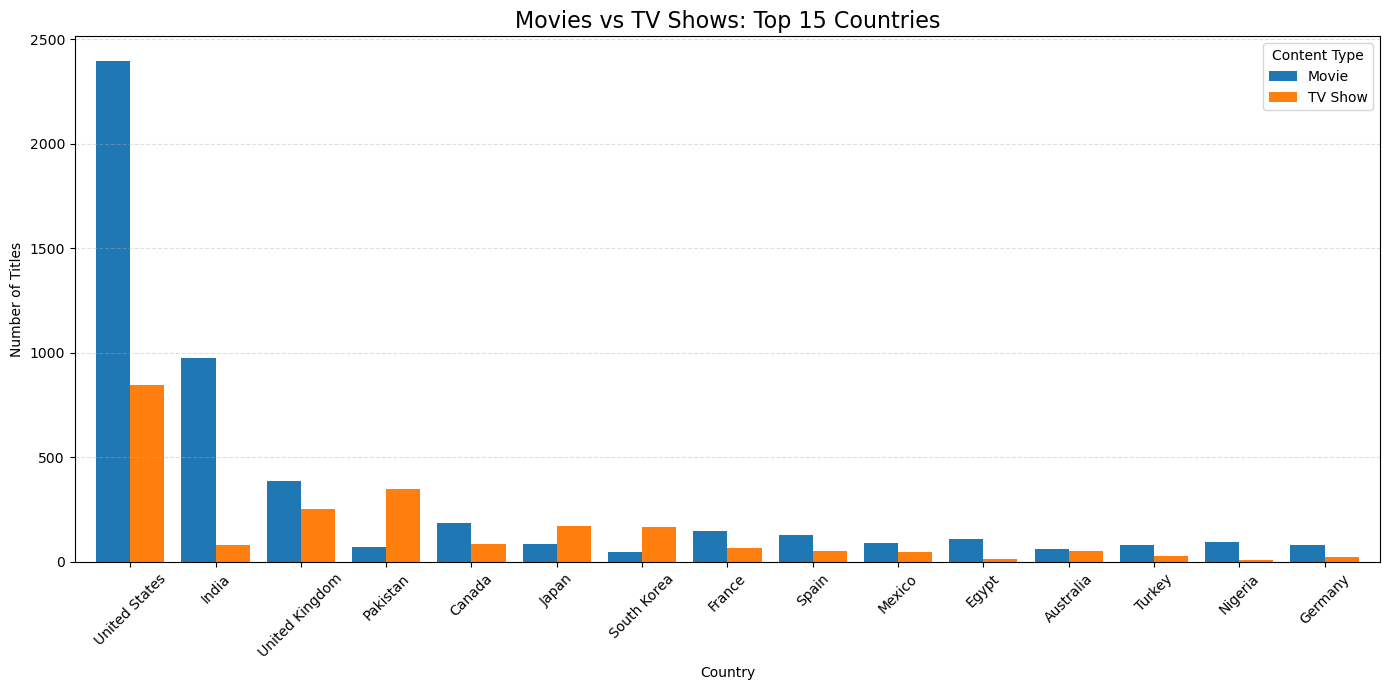

In [10]:
top_15_countries = country_type.loc[
    country_counts.head(15).index
]

top_15_countries.plot(
    kind='bar',
    figsize=(14, 7),
    width=0.8
)

plt.title("Movies vs TV Shows: Top 15 Countries", fontsize=16)
plt.xlabel("Country")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.legend(title="Content Type")
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

## 7. Top 10 Countries by Movies and TV Shows

The top 10 countries are identified separately based on their Movie and TV Show counts.

This analysis helps compare the leading countries in Movie production and TV Show production on Netflix.

In [11]:
top_movie_countries = country_type['Movie'].sort_values(
    ascending=False
).head(10)

top_tv_countries = country_type['TV Show'].sort_values(
    ascending=False
).head(10)

print("Top 10 Countries by Movies:")
display(top_movie_countries)

print("Top 10 Countries by TV Shows:")
display(top_tv_countries)

Top 10 Countries by Movies:


country
United States     2395
India              976
United Kingdom     387
Canada             187
France             148
Spain              129
Egypt              109
Nigeria             96
Mexico              90
Japan               87
Name: Movie, dtype: int64

Top 10 Countries by TV Shows:


country
United States     845
Pakistan          350
United Kingdom    251
Japan             172
South Korea       165
Canada             84
India              81
Taiwan             71
France             65
Australia          53
Name: TV Show, dtype: int64

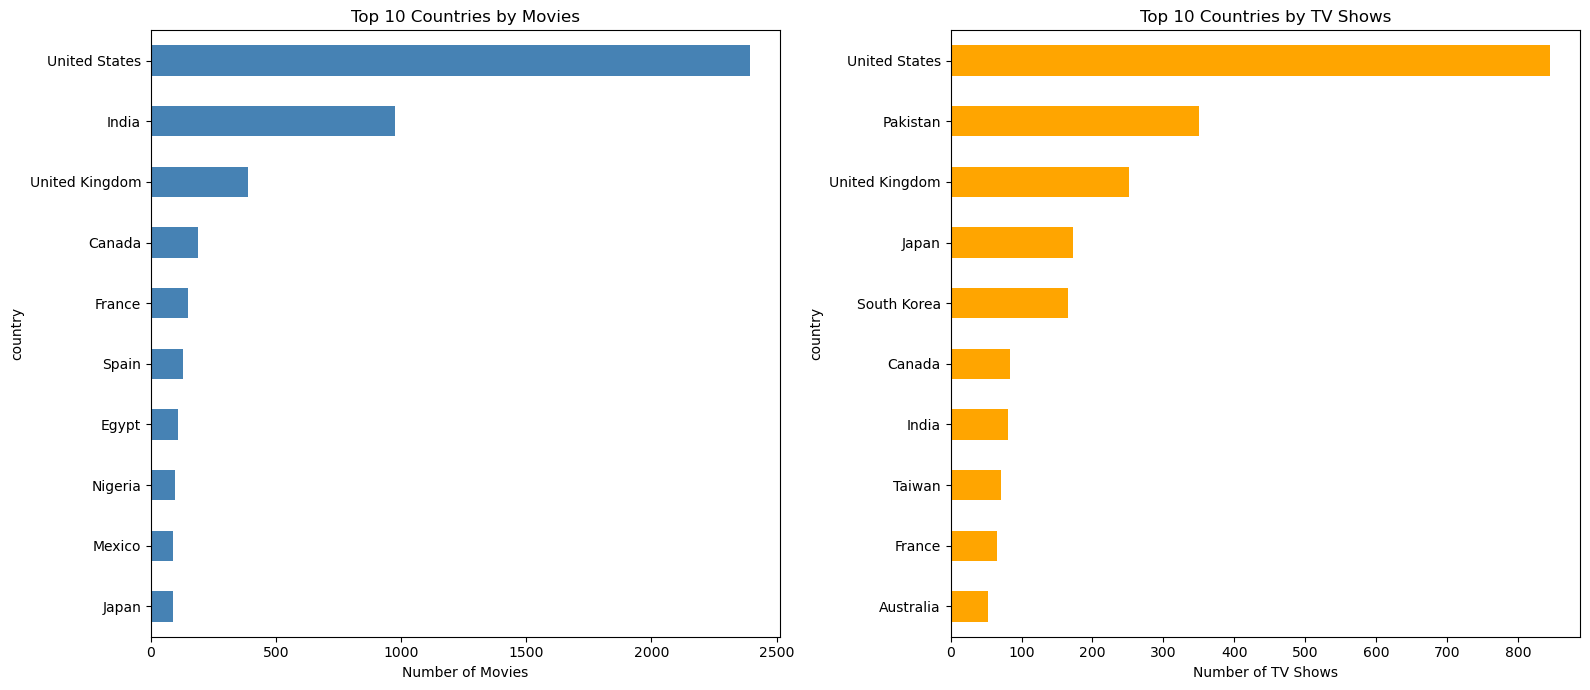

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

top_movie_countries.sort_values().plot(
    kind='barh',
    ax=axes[0],
    color='steelblue'
)

axes[0].set_title("Top 10 Countries by Movies")
axes[0].set_xlabel("Number of Movies")

top_tv_countries.sort_values().plot(
    kind='barh',
    ax=axes[1],
    color='orange'
)

axes[1].set_title("Top 10 Countries by TV Shows")
axes[1].set_xlabel("Number of TV Shows")

plt.tight_layout()
plt.show()

## 8. Country-Wise Summary Analysis

A summary table is created to display the total number of Netflix titles, Movies, and TV Shows for each country.

The percentage distribution of Movies and TV Shows is also calculated to understand the content preferences across different countries.

In [13]:
country_summary = pd.DataFrame({
    'Total Titles': country_counts,
    'Movies': country_type['Movie'],
    'TV Shows': country_type['TV Show']
})

country_summary['Movie Percentage'] = (
    country_summary['Movies'] / country_summary['Total Titles'] * 100
)

country_summary['TV Show Percentage'] = (
    country_summary['TV Shows'] / country_summary['Total Titles'] * 100
)

country_summary.sort_values(
    by='Total Titles',
    ascending=False
).head(10).round(2)

,Total Titles,Movies,TV Shows,Movie Percentage,TV Show Percentage
country,,,,,
United States,3240,2395,845,73.92,26.08
India,1057,976,81,92.34,7.66
United Kingdom,638,387,251,60.66,39.34
Pakistan,421,71,350,16.86,83.14
Canada,271,187,84,69.00,31.00
Japan,259,87,172,33.59,66.41
South Korea,214,49,165,22.90,77.10
France,213,148,65,69.48,30.52
Spain,182,129,53,70.88,29.12


In [14]:
country_summary.to_csv(
    "output/Country_Wise_Summary.csv"
)

print("Country-wise summary exported successfully!")

Country-wise summary exported successfully!


## 9. Final Data Validation

The final dataset is validated to check its dimensions, missing values, duplicate records, and the total number of countries analyzed.

These checks help ensure the reliability and consistency of the analysis results.

In [15]:
print("Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Total Countries:", country_counts.shape[0])
print("Summary Records:", country_summary.shape[0])

Dataset Shape: (8790, 10)
Missing Values: 0
Duplicate Rows: 0
Total Countries: 85
Summary Records: 85


## 10. Key Findings and Conclusion

### Key Findings

- The United States has the highest number of Netflix titles.
- India ranks second in total Netflix content.
- The United States leads in both Movies and TV Shows.
- India has a higher proportion of Movies (92.34%).
- Pakistan has a higher proportion of TV Shows (83.14%).
- Japan and South Korea also have a strong TV Show distribution.

### Conclusion

This analysis provides insights into the country-wise distribution of Netflix Movies and TV Shows. It highlights the leading content-producing countries and compares their content distribution using Python, Pandas, Matplotlib, and Seaborn.

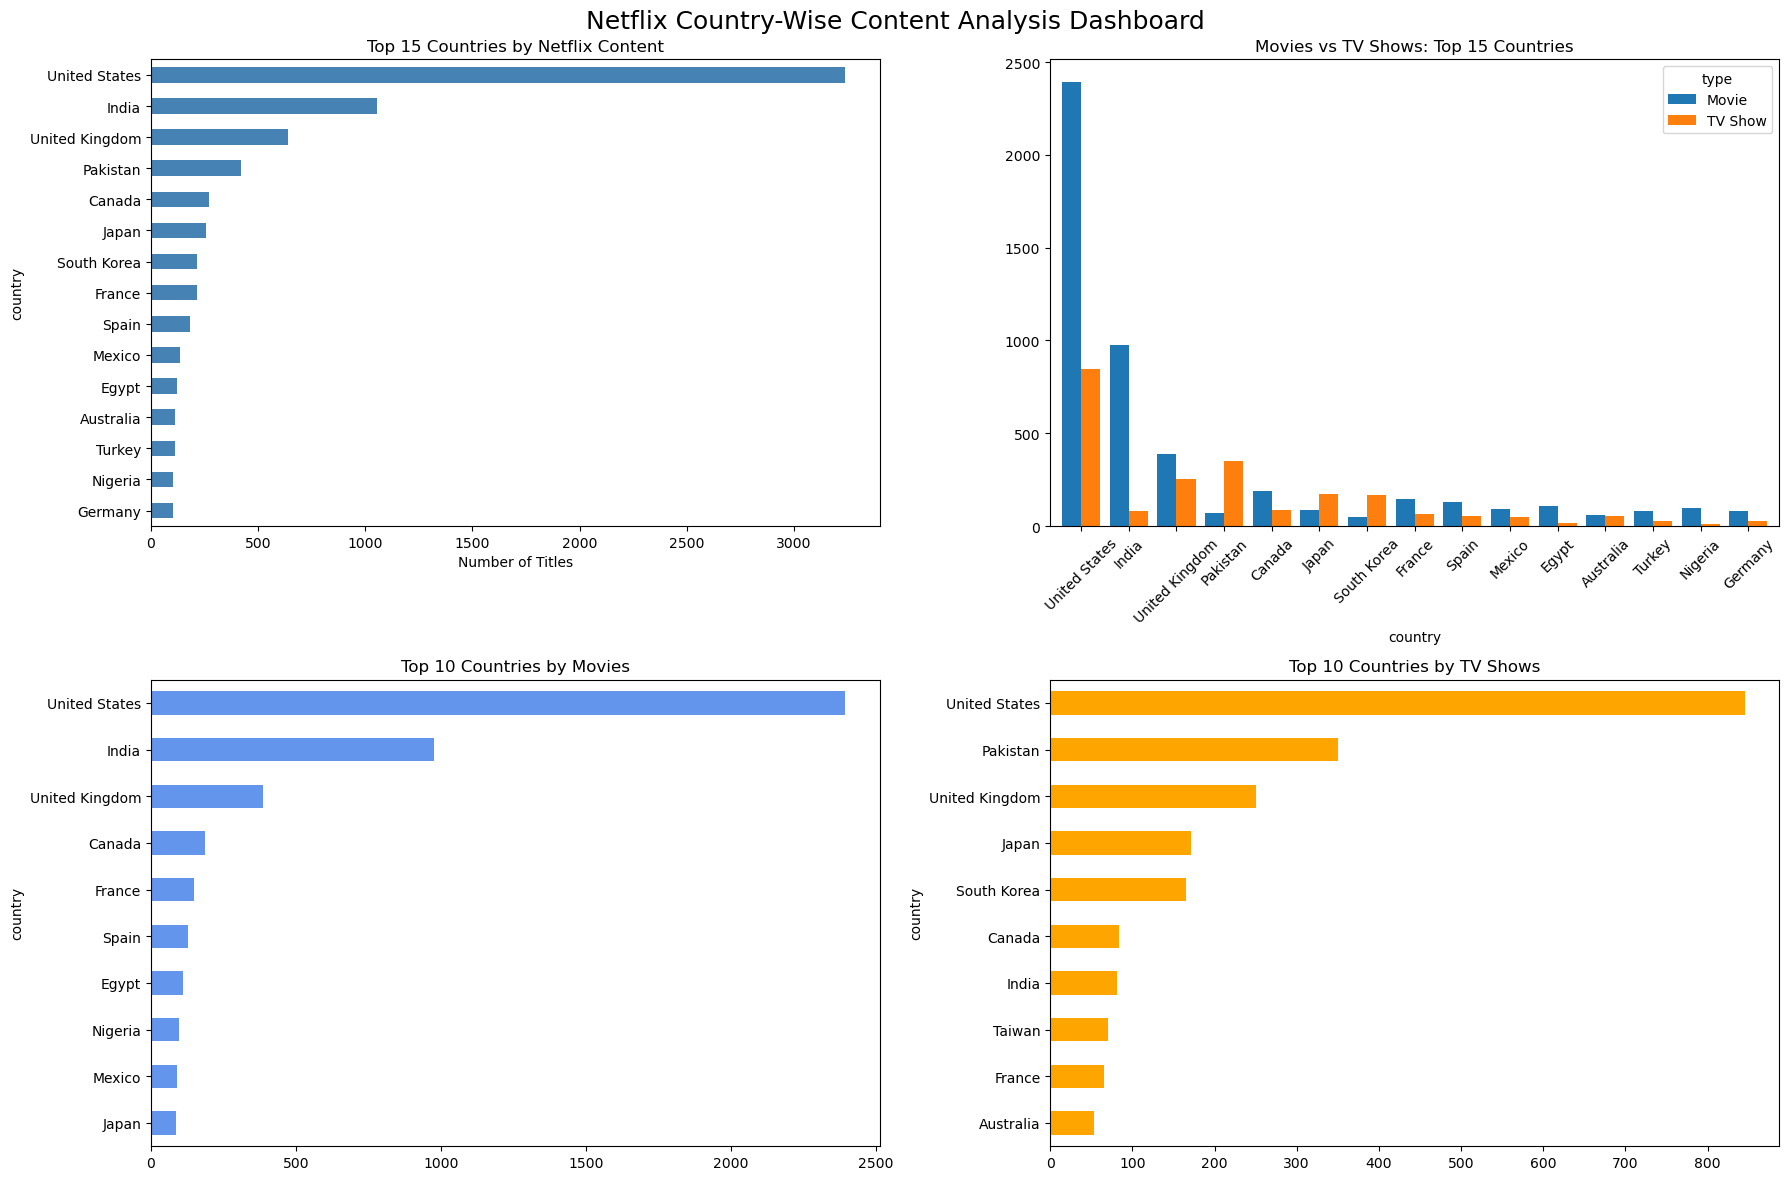

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# 1. Top 15 Countries
country_counts.head(15).sort_values().plot(
    kind='barh',
    ax=axes[0, 0],
    color='steelblue'
)
axes[0, 0].set_title("Top 15 Countries by Netflix Content")
axes[0, 0].set_xlabel("Number of Titles")

# 2. Movies vs TV Shows
top_15_countries.plot(
    kind='bar',
    ax=axes[0, 1],
    width=0.8
)
axes[0, 1].set_title("Movies vs TV Shows: Top 15 Countries")
axes[0, 1].tick_params(axis='x', rotation=45)

# 3. Top 10 Movie Countries
top_movie_countries.sort_values().plot(
    kind='barh',
    ax=axes[1, 0],
    color='cornflowerblue'
)
axes[1, 0].set_title("Top 10 Countries by Movies")

# 4. Top 10 TV Show Countries
top_tv_countries.sort_values().plot(
    kind='barh',
    ax=axes[1, 1],
    color='orange'
)
axes[1, 1].set_title("Top 10 Countries by TV Shows")

fig.suptitle(
    "Netflix Country-Wise Content Analysis Dashboard",
    fontsize=18
)

plt.tight_layout()
plt.savefig(
    "output/Country_Wise_Dashboard.png",
    dpi=300,
    bbox_inches='tight'
)
plt.show()